<a href="https://colab.research.google.com/github/SumaiyaObayed/house-price-prediction/blob/main/Sumaiya_Obayed_CSEJNUP_%7C_01_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Title: House Price prediction Using LR, RF and RGB Algorithms.**


**Objective:**
To predict house prices in real estate markets, such as Sydney and Melbourne, using machine learning algorithms, including Linear Regression (LR), Random Forest (RF), and XGBoost (XGB). The prediction of property prices is crucial as it reflects market conditions and economic health, helping investors and policymakers make informed decisions.

**Summary:**
The dataset represents real estate market trends, providing valuable insights into property sales and pricing dynamics. It consists of 2000 entries with 10 columns, including numerical and categorical variables such as area, number of bedrooms, bathrooms, floors, location, and condition. Given the unknown format and potential data quality issues, thorough data wrangling was performed to clean and prepare the dataset for analysis.

The workflow begins by importing essential libraries like NumPy, Pandas, and Scikit-learn for data manipulation, visualization, and model building. The dataset is read into a Pandas DataFrame, followed by an initial examination of its structure, data types, and summary statistics. In the Exploratory Data Analysis (EDA) phase, categorical variables such as Location, Condition, and Garage were encoded, and numerical features were analyzed for their correlation with house prices. Data preprocessing ensured that missing values and duplicates were handled effectively.

Feature selection techniques, including correlation analysis and Random Forest feature importance, were applied to identify the most influential predictors of house prices. The dataset was then split into training and testing sets, and three machine learning models—Linear Regression (LR), Random Forest (RF), and XGBoost (XGB)—were trained and evaluated. Performance was assessed based on Mean Squared Error (MSE) and R² scores. Initial results showed that Random Forest performed better than Linear Regression, capturing non-linear relationships more effectively.

This workflow demonstrates a structured approach to predicting house prices using machine learning, covering data wrangling, feature selection, model training, evaluation, and performance comparison to provide insights into real estate market trends.





Name: SUMAIYA OBAYED
Batch:CSEJNUP | 01




**Dataset Source:** https://www.kaggle.com/code/aasmak/house-price-pred/input


#Importing Libraries:

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb
import seaborn as sns
import matplotlib.pyplot as plt

#Loading Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
Data= pd.read_csv("/content/drive/MyDrive/House Price Prediction Dataset.csv")

In [ ]:
Data.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [ ]:
Data.shape

(2000, 10)

In [ ]:
Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         2000 non-null   int64 
 1   Area       2000 non-null   int64 
 2   Bedrooms   2000 non-null   int64 
 3   Bathrooms  2000 non-null   int64 
 4   Floors     2000 non-null   int64 
 5   YearBuilt  2000 non-null   int64 
 6   Location   2000 non-null   object
 7   Condition  2000 non-null   object
 8   Garage     2000 non-null   object
 9   Price      2000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 156.4+ KB


In [ ]:
Data.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [ ]:
Data.isnull().sum()

,0
Id,0
Area,0
Bedrooms,0
Bathrooms,0
Floors,0
YearBuilt,0
Price,0
Location_Rural,0
Location_Suburban,0
Location_Urban,0


#Exploratory data Analysis(EDA)

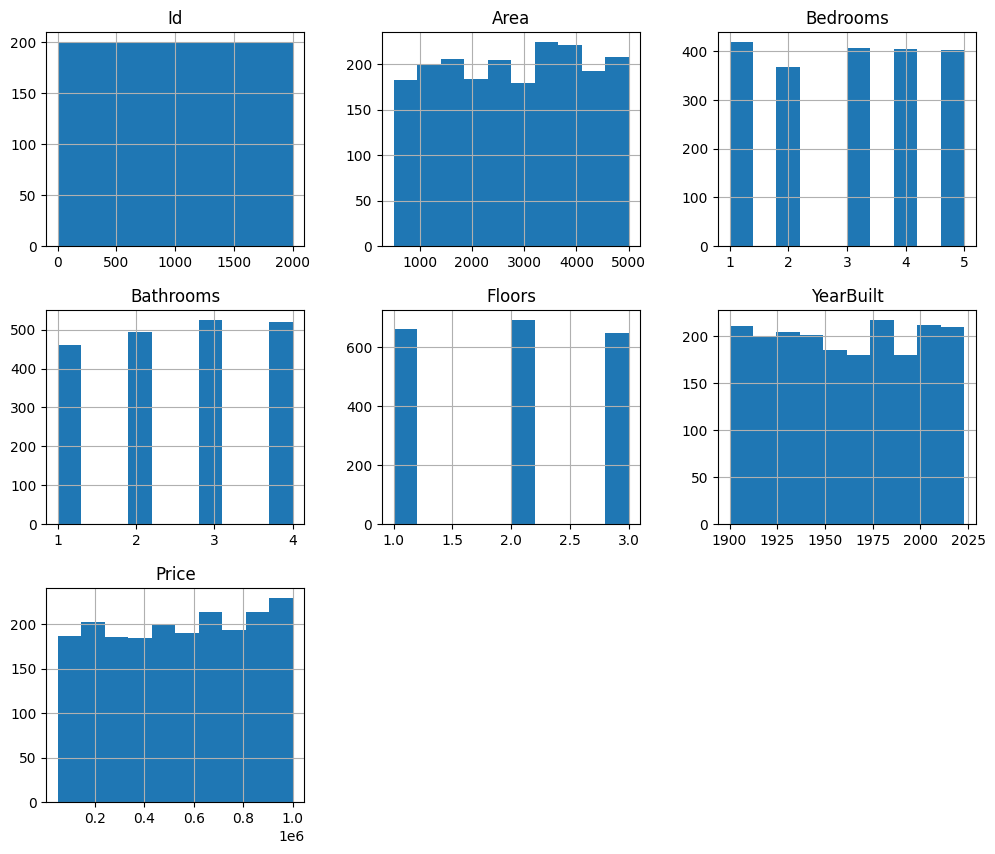

In [ ]:
#Showing Data Distribution
Data.hist(figsize=(12, 10))
plt.show()

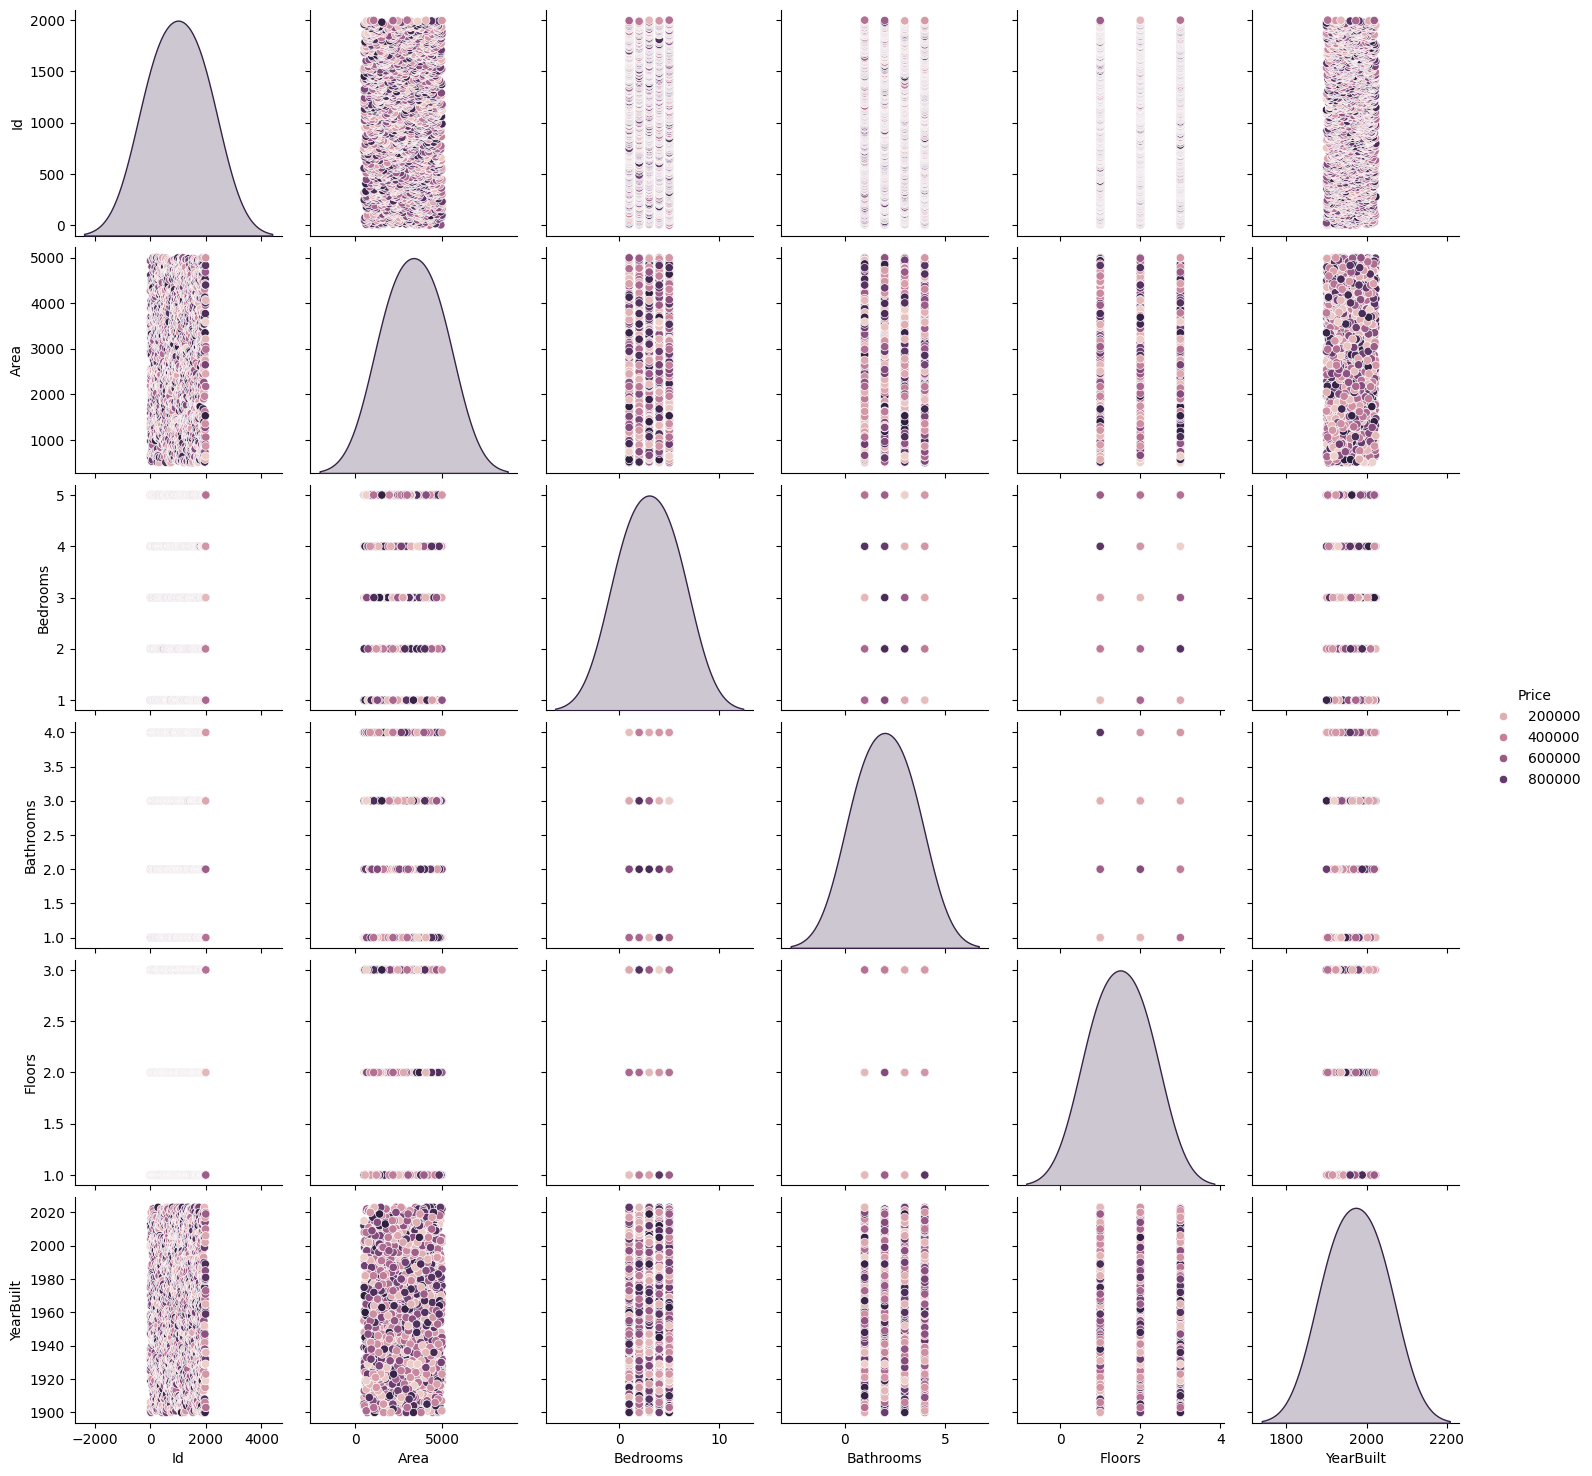

In [ ]:
# Showing Relationship with scatter-plot
sns.pairplot(Data, hue='Price')
plt.show()

#Encoding Catagorical Features

In [ ]:
Data = pd.get_dummies(Data, columns=['Location', 'Condition', 'Garage'], drop_first=True)

In [ ]:
Data

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1,1360,5,4,3,1970,149919,False,False,False,False,False,False,False
1,2,4272,5,4,3,1958,424998,False,False,False,False,False,False,False
2,3,3592,2,2,3,1938,266746,False,False,False,False,True,False,False
3,4,966,4,2,2,1902,244020,False,True,False,True,False,False,True
4,5,4926,1,4,2,1975,636056,False,False,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3,1923,295620,False,True,False,False,False,True,False
1996,1997,3046,5,2,1,2019,580929,False,True,False,False,False,True,True
1997,1998,1062,5,1,2,1903,476925,True,False,False,False,False,True,False
1998,1999,4062,3,1,2,1936,161119,False,False,True,False,False,False,True


In [ ]:
#Removing Duplicates
Data.drop_duplicates(inplace=True)
Data

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1,1360,5,4,3,1970,149919,False,False,False,False,False,False,False
1,2,4272,5,4,3,1958,424998,False,False,False,False,False,False,False
2,3,3592,2,2,3,1938,266746,False,False,False,False,True,False,False
3,4,966,4,2,2,1902,244020,False,True,False,True,False,False,True
4,5,4926,1,4,2,1975,636056,False,False,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,1996,4994,5,4,3,1923,295620,False,True,False,False,False,True,False
1996,1997,3046,5,2,1,2019,580929,False,True,False,False,False,True,True
1997,1998,1062,5,1,2,1903,476925,True,False,False,False,False,True,False
1998,1999,4062,3,1,2,1936,161119,False,False,True,False,False,False,True


#Feature Selection

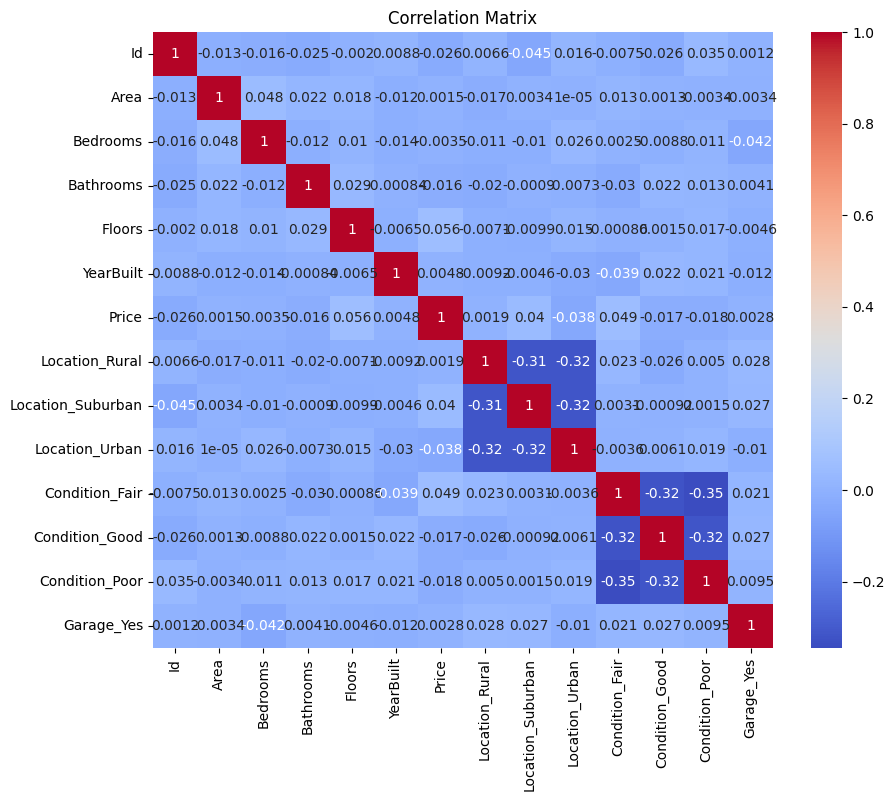

In [ ]:
#correlation
correlation_matrix = Data.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

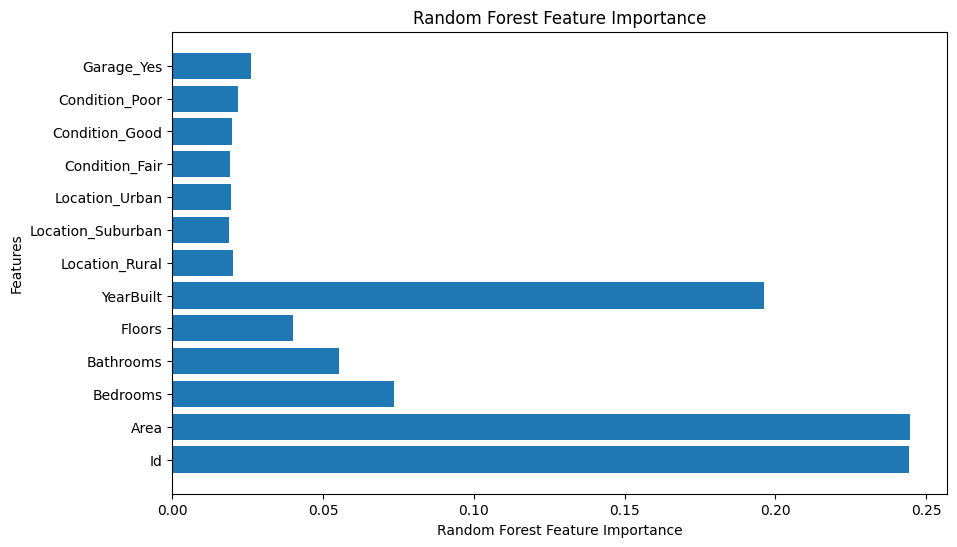

In [ ]:
#Random Forest Importance
X = Data.drop('Price', axis=1)
y = Data['Price']
rf_model = RandomForestRegressor()
rf_model.fit(X, y) # X=feature matrix, y=target variable
feature_importances = rf_model.feature_importances_
plt.figure(figsize=(10, 6))
plt.barh(X.columns, feature_importances)
plt.xlabel('Random Forest Feature Importance')
plt.ylabel('Features')
plt.title('Random Forest Feature Importance')
plt.show()

#Splitting Training and Testing Sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
X,y

(        Id  Area  Bedrooms  Bathrooms  Floors  YearBuilt  Location_Rural  \
 0        1  1360         5          4       3       1970           False   
 1        2  4272         5          4       3       1958           False   
 2        3  3592         2          2       3       1938           False   
 3        4   966         4          2       2       1902           False   
 4        5  4926         1          4       2       1975           False   
 ...    ...   ...       ...        ...     ...        ...             ...   
 1995  1996  4994         5          4       3       1923           False   
 1996  1997  3046         5          2       1       2019           False   
 1997  1998  1062         5          1       2       1903            True   
 1998  1999  4062         3          1       2       1936           False   
 1999  2000  2989         5          1       3       1903           False   
 
       Location_Suburban  Location_Urban  Condition_Fair  Condition_Good  

#Model Evaluation

In [ ]:
# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)
lr_mse = mean_squared_error(y_test, lr_predictions)
lr_r2 = r2_score(y_test, lr_predictions)
print("Linear Regression - Mean Squared Error:", lr_mse)
print("Linear Regression - R² Score:", lr_r2)

Linear Regression - Mean Squared Error: 78279764120.86243
Linear Regression - R² Score: -0.006181784611834162


In [ ]:
# Random Forest with hyperparameter Tuning
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10]
}
grid_search_rf = GridSearchCV(estimator=RandomForestRegressor(random_state=42),
                              param_grid=param_grid_rf, scoring='neg_mean_squared_error', cv=5)
grid_search_rf.fit(X_train, y_train)
best_rf_model = grid_search_rf.best_estimator_
rf_predictions = best_rf_model.predict(X_test)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions)
print("Random Forest - Mean Squared Error:", rf_mse)

Random Forest - Mean Squared Error: 79556347625.52003


In [ ]:

# XGBoost with Hyperparameter Tuning
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 4, 5]
}
grid_search_xgb = GridSearchCV(estimator=xgb.XGBRegressor(random_state=42),
                               param_grid=param_grid_xgb, scoring='neg_mean_squared_error', cv=5)
grid_search_xgb.fit(X_train, y_train)
best_xgb_model = grid_search_xgb.best_estimator_
xgb_predictions = best_xgb_model.predict(X_test)
xgb_mse = mean_squared_error(y_test, xgb_predictions)
xgb_r2 = r2_score(y_test, xgb_predictions)
print("XGBoost - Mean Squared Error:", xgb_mse)

XGBoost - Mean Squared Error: 78419337216.0


#comparing Results

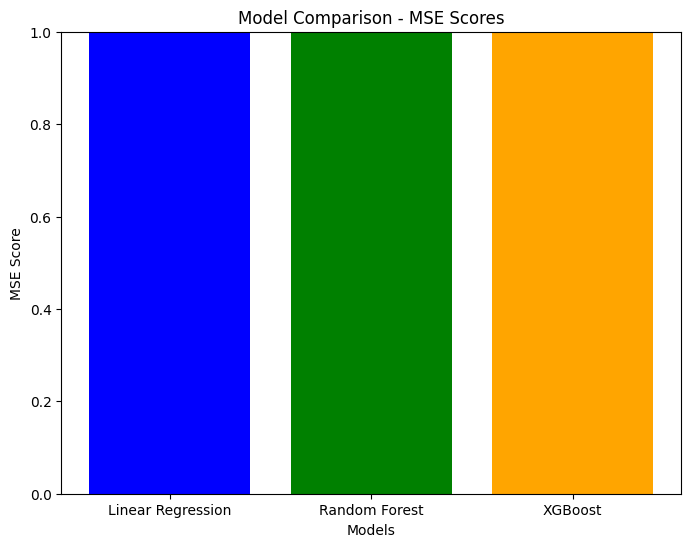

In [ ]:
models = ['Linear Regression', 'Random Forest', 'XGBoost']
mse_scores = [lr_mse, rf_mse, xgb_mse]
plt.figure(figsize=(8, 6))
plt.bar(models, mse_scores, color=['blue', 'green', 'orange'])
plt.title('Model Comparison - MSE Scores')
plt.xlabel('Models')
plt.ylabel('MSE Score')
plt.ylim(0, 1)
plt.show()
